# Part 1
Part 1 of this notebook is split into 3 sections: initial hyperparameter tuning, focussed hyperparameter tuning and evaluation. 
<!-- WRITE SOME MORE STUFF!!! -->

This notebook follows a two-stage model selection strategy. In the first stage, the CNN is trained on reduced-resolution images to efficiently explore a broad architecture space and identify promising hyperparameter regions. This reduced search is computationally efficient and enables rapid comparison across candidate configurations without the cost of repeated full-resolution training.

In the second stage, the most promising configurations are retrained on full-resolution images with augmentation to evaluate their generalisation performance under more realistic image conditions. This staged approach balances computational tractability with methodological rigor and is particularly appropriate for image classification tasks where larger inputs increase both memory and training time.

In [ ]:
from pathlib import Path

import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.datasets import load_sample_images
from PIL import Image
import keras
import numpy as np
from collections import Counter

import keras_tuner as kt
import pandas as pd

In [2]:
# Resolution-safe defaults for this notebook.
NOTEBOOK_DIR = Path.cwd()
TRAIN_DIR = NOTEBOOK_DIR / 'train'
VALID_DIR = NOTEBOOK_DIR / 'valid'
TEST_DIR = NOTEBOOK_DIR / 'test'
BASE_MODEL_PATH = NOTEBOOK_DIR / 'CNN_A.keras'

print(f'Base model exists: {BASE_MODEL_PATH.exists()}')
print(f'Train directory exists: {TRAIN_DIR.exists()}')

# Force CPU before tuner/model creation to avoid Metal GPU timeout errors on macOS.
tf.keras.backend.clear_session()
try:
    tf.config.list_physical_devices("GPU")
    print("Using GPU for model creation and tuning.")
except RuntimeError:
    print("Using CPU for model creation and tuning.")
    pass

plt.rcParams['font.size'] = 14
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['legend.fontsize'] = 12


Base model exists: False
Train directory exists: True
Using GPU for model creation and tuning.


### Part 1a: Initial Hyperparameter Tuning  
- Load the train, test and validation sets in a reduced resolution for faster hyperparameter tuning
- Complete hyperparameter tuning on a smaller search space
- Conclude which hyperparameter/structures have been successful

In [ ]:
# import the images for tuning 
train_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)
val_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)
test_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

X_train = train_gen.flow_from_directory(
    './train',
    target_size=(128, 128),
    batch_size=32,

)
X_test = test_gen.flow_from_directory(
    './test',
    target_size=(128, 128),
    batch_size=32   
)
X_valid = val_gen.flow_from_directory(
    './valid',
    target_size=(128, 128),
    batch_size=32
)

Found 1546 images belonging to 10 classes.
Found 50 images belonging to 10 classes.
Found 50 images belonging to 10 classes.


Text(0.5, 1.0, 'Test Image')

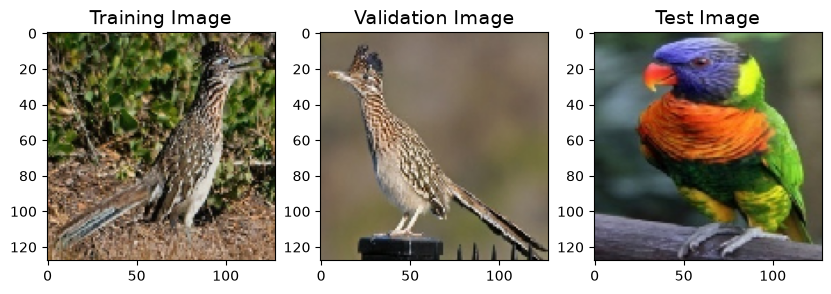

In [4]:
# display the first image in each set
plt.figure(figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.imshow(X_train[0][0][0])
plt.title('Training Image')
plt.subplot(1, 3, 2)
plt.imshow(X_valid[0][0][0])
plt.title('Validation Image')
plt.subplot(1, 3, 3)
plt.imshow(X_test[0][0][0])
plt.title('Test Image')

Initial Hyperparameters:  
- number of blocks (1 to 4)
- filter size (32, 64 or 128)
- kernel size (3 or 5)
- dense units (64 or 128)
- learning rate (between 0.0001 and 0.000001)

The some of the hyperparameters chosen will be used for candidates for the final model 

In [5]:
def build_candidate_model(hp):
    inputs = tf.keras.Input(shape=(128, 128, 3))
    x = inputs

    for i in range(hp.Int("num_blocks", 1, 4)):
        x = tf.keras.layers.Conv2D(
            hp.Choice(f"filters_{i}", [32, 64, 128]),
            kernel_size=hp.Choice(f"kernel_{i}", [3, 5]),
            padding="same",
            activation="relu"
        )(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(
        hp.Choice("dense_units", [64, 128]),
        activation="relu"
    )(x)
    x = tf.keras.layers.Dropout(
        hp.Float("dropout", 0.2, 0.5, step=0.1)
    )(x)
    outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Float("learning_rate", 1e-5, 1e-3, sampling="log")
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [ ]:
# %%time
tuner = kt.Hyperband(
    build_candidate_model,
    objective="val_accuracy",
    max_epochs=25,
    factor=3,
    directory="keras_tuner_results",
    project_name="image_classifier_fast"
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

tuner.search(
    X_train,
    validation_data=(X_valid),
    callbacks=[early_stopping]
)

best_model = tuner.get_best_models(num_models=1)[0]
print(best_model.summary())

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

# Save the best fast-model architecture as an image for reporting.
try:
    tf.keras.utils.plot_model(
        best_model,
        to_file="best_fast_model_architecture.png",
        show_shapes=True,
        show_dtype=False,
        show_layer_names=True,
        rankdir="TB",
        expand_nested=False,
        dpi=150,
    )
    print("Saved best fast-model architecture to best_fast_model_architecture.png")
except Exception as e:
    print(f"Could not save best fast-model architecture: {e}")

Trial 30 Complete [00h 08m 15s]
val_accuracy: 0.699999988079071

Best val_accuracy So Far: 0.9200000166893005
Total elapsed time: 01h 12m 38s


/Users/lauryn/Documents/advanced_ml/venv/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 42 variables. 
  saveable.load_own_variables(store)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 128)    │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │       102,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 196,394 (767.16 KB)

 Trainable params: 195,754 (764.66 KB)

 Non-trainable params: 640 (2.50 KB)

None


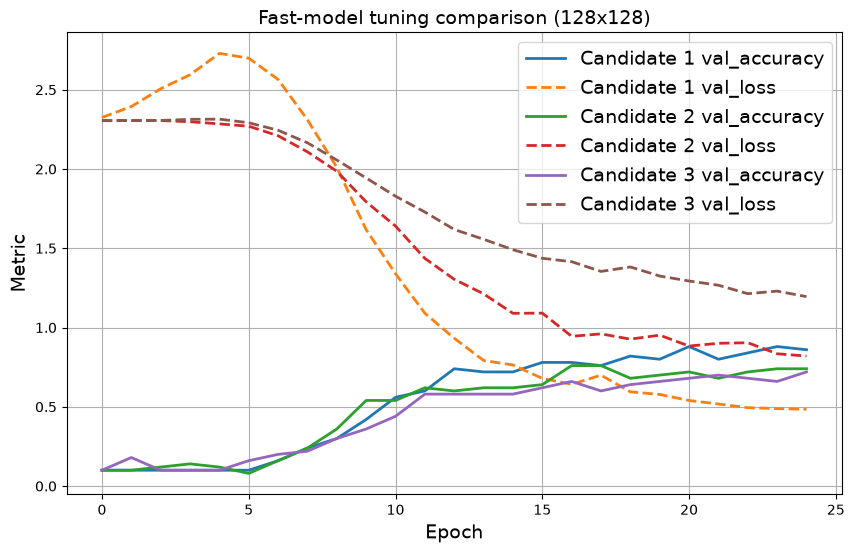

Top 3 fast-model validation accuracies:
Candidate 1: 0.8800
Candidate 2: 0.7600
Candidate 3: 0.7200


In [ ]:
# Plot the fast tuning results (128x128)
fast_histories = []
trial_scores = []

# Rebuild and train the top 5 fast models to collect learning curves
for i, hp in enumerate(tuner.get_best_hyperparameters(num_trials=3), 1):
    model = build_candidate_model(hp)
    history = model.fit(
        X_train,
        validation_data=X_valid,
        epochs=25,
        callbacks=[early_stopping],
        verbose=0
    )
    fast_histories.append(history)
    trial_scores.append((i, max(history.history["val_accuracy"])))

plt.figure(figsize=(10, 6))
colors = plt.cm.Purples(np.linspace(0.35, 0.95, len(fast_histories)))

for i, history in enumerate(fast_histories, 1):
    epochs = np.arange(len(history.history["val_accuracy"]))
    color = colors[i - 1]
    plt.plot(
        epochs,
        history.history["val_accuracy"],
        label=f"Candidate {i} accuracy",
        color=color,
        linewidth=2
    )
    plt.plot(
        epochs,
        history.history["val_loss"],
        linestyle="--",
        label=f"Candidate {i} loss",
        color=color,
        linewidth=2
    )

plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("Fast-model tuning comparison (128x128)")
plt.legend(loc="upper right", fontsize=8, ncol=2)
plt.grid(True)
plt.show()

print("Top 3 fast-model validation accuracies:")
for i, score in trial_scores:
    print(f"Candidate {i}: {score:.4f}")

In [26]:
# Optional: print the top 5 tuned configurations for reporting
best_hps = tuner.get_best_hyperparameters(num_trials=5)

hp_rows = []
for i, hp in enumerate(best_hps, 1):
    row = {"candidate": i}
    row.update(hp.values)
    hp_rows.append(row)

hp_df = pd.DataFrame(hp_rows)
hp_df


,candidate,num_blocks,filters_0,kernel_0,dense_units,dropout,learning_rate,filters_1,kernel_1,filters_2,kernel_2,filters_3,kernel_3,tuner/epochs,tuner/initial_epoch,tuner/bracket,tuner/round,tuner/trial_id
0,1,4,32,3,128,0.3,0.000077,128,3,32,5,128,3,25,0,0,0,NaN
1,2,2,32,5,128,0.2,0.000068,128,5,32,3,32,5,25,9,1,1,0020
2,3,4,32,5,128,0.2,0.000016,128,5,64,5,32,3,25,0,0,0,NaN
3,4,3,128,5,128,0.4,0.000015,128,3,128,5,32,5,25,0,0,0,NaN
4,5,1,64,5,128,0.2,0.000907,128,3,32,5,32,3,25,9,2,2,0012


### Interpretation of tuning results

The reduced-resolution tuning stage is intended to act as a screening mechanism rather than a final performance estimate. Hyperparameter rankings at this stage are informative for identifying promising architectural families, but they are not assumed to be identical to the rankings obtained when training on the full-resolution dataset. This is because increasing spatial resolution changes the feature distribution and can alter the relative effectiveness of depth, filter size, and regularisation.

In particular, deeper architectures may require additional epochs to converge and may not appear among the top-ranked models under short tuning budgets. For this reason, the final model selection is performed after retraining the best-performing configurations on full-size images, where the validation signal reflects the model's true generalisation behaviour under the final image resolution.


## Part 1b: Focussed Hyperparameter Tuning 
- Compare the best performing models from the tuning using the full size images
- Comparison of the deeper models using the full size images

The reduced-resolution search was used to efficiently explore the architecture space. The best-performing configurations will be retrained on full-size images to determine the final model for reporting. We will also do a comparison of the deeper architectures 

In [ ]:
# Load the full-size images for the final model comparison
train_full = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_full = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)
test_full = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

X_train_full = train_full.flow_from_directory(
    './train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

X_test_full = test_full.flow_from_directory(
    './test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

X_valid_full = val_full.flow_from_directory(
    './valid',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

# Check whether the class distribution is balanced across the dataset.

train_counts = Counter()
valid_counts = Counter()
test_counts = Counter()

for split_name, directory in [('train', TRAIN_DIR), ('valid', VALID_DIR), ('test', TEST_DIR)]:
    for class_dir in sorted(directory.iterdir()):
        if class_dir.is_dir():
            count = len(list(class_dir.glob('*')))
            if split_name == 'train':
                train_counts[class_dir.name] = count
            elif split_name == 'valid':
                valid_counts[class_dir.name] = count
            else:
                test_counts[class_dir.name] = count

print('Train class counts:', dict(train_counts))
print('Validation class counts:', dict(valid_counts))
print('Test class counts:', dict(test_counts))

train_balanced = len(set(train_counts.values())) == 1
valid_balanced = len(set(valid_counts.values())) == 1
test_balanced = len(set(test_counts.values())) == 1

print(f"Train balanced: {train_balanced}")
print(f"Validation balanced: {valid_balanced}")
print(f"Test balanced: {test_balanced}")

# Compute a class-weight dictionary based on the imbalanced training split.
# This down-weights majority classes without duplicating images or altering the
# original dataset distribution.
class_indices = X_train_full.class_indices
class_weights = {}
train_total = sum(train_counts.values())
num_classes = len(train_counts)

for class_name, idx in class_indices.items():
    class_count = train_counts[class_name]
    class_weights[idx] = train_total / (num_classes * class_count)

print("Class weights:", class_weights)


Found 1546 images belonging to 10 classes.
Found 50 images belonging to 10 classes.
Found 50 images belonging to 10 classes.


### Class imbalance handling
The training split is mildly imbalanced, so we use class weighting rather than duplicating images. This approach reduces the influence of majority classes while preserving the original data distribution and avoiding artificial inflation of the training set.

Text(0.5, 1.0, 'Test Image')

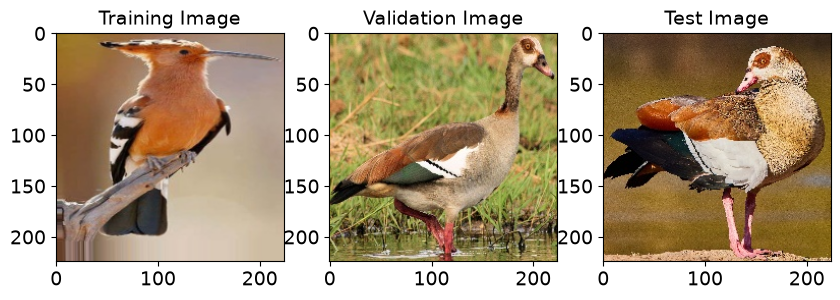

In [5]:
# display the first image in each set
plt.figure(figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.imshow(X_train_full[0][0][0])
plt.title('Training Image')
plt.subplot(1, 3, 2)
plt.imshow(X_valid_full[0][0][0])
plt.title('Validation Image')
plt.subplot(1, 3, 3)
plt.imshow(X_test_full[0][0][0])
plt.title('Test Image')


Training candidate 1 on full-size data...
Epoch 1/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 23s 440ms/step - accuracy: 0.2180 - loss: 2.1896 - val_accuracy: 0.1000 - val_loss: 2.3039
Epoch 2/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 23s 458ms/step - accuracy: 0.3752 - loss: 1.8503 - val_accuracy: 0.1000 - val_loss: 2.3400
Epoch 3/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 22s 443ms/step - accuracy: 0.4625 - loss: 1.6531 - val_accuracy: 0.1000 - val_loss: 2.4143
Epoch 4/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 21s 436ms/step - accuracy: 0.4987 - loss: 1.5302 - val_accuracy: 0.1000 - val_loss: 2.5403
Epoch 5/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 22s 439ms/step - accuracy: 0.5194 - loss: 1.4457 - val_accuracy: 0.1000 - val_loss: 2.6179
Epoch 6/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 22s 438ms/step - accuracy: 0.5524 - loss: 1.3542 - val_accuracy: 0.1000 - val_loss: 2.6591
Epoch 7/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 22s 441ms/step - accuracy: 0.5977 - loss: 1.2744 - val_accuracy: 0.1000 - val_loss: 2.5305
Epoch 8/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 22s 441ms/step -

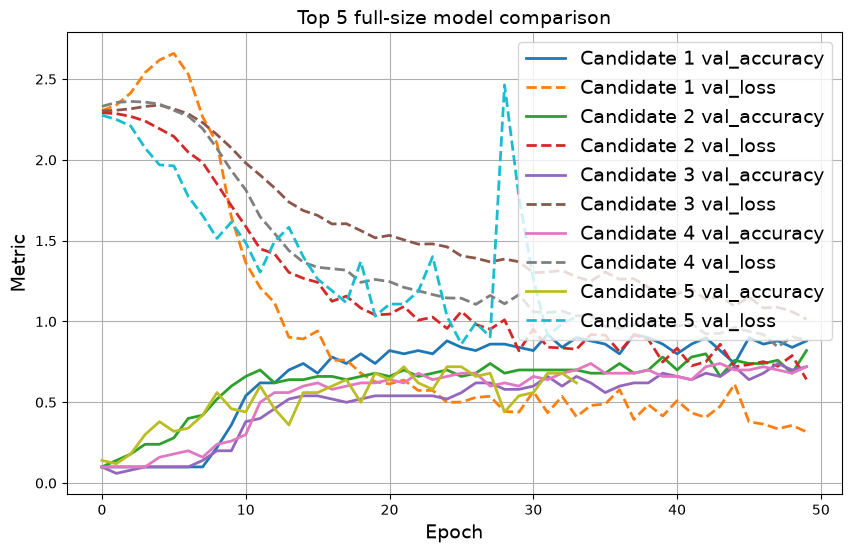

In [ ]:
top_hps = tuner.get_best_hyperparameters(num_trials=5)
all_histories = []
results = []
trained_full_models = []

for i, hp in enumerate(top_hps, 1):
    print(f"\nTraining candidate {i} on full-size data...")

    def build_candidate_model_full():
        inputs = tf.keras.Input(shape=(224, 224, 3))
        x = inputs

        for j in range(hp.get("num_blocks")):
            x = tf.keras.layers.Conv2D(
                hp.get(f"filters_{j}"),
                kernel_size=hp.get(f"kernel_{j}"),
                padding="same",
                activation="relu"
            )(x)
            x = tf.keras.layers.BatchNormalization()(x)
            x = tf.keras.layers.MaxPooling2D()(x)

        x = tf.keras.layers.GlobalAveragePooling2D()(x)
        x = tf.keras.layers.Dense(hp.get("dense_units"), activation="relu")(x)
        x = tf.keras.layers.Dropout(hp.get("dropout"))(x)
        outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

        model = tf.keras.Model(inputs, outputs)
        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=hp.get("learning_rate")
            ),
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )
        return model

    model = build_candidate_model_full()

    history = model.fit(
        X_train_full,
        validation_data=X_valid_full,
        epochs=50,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True
            )
        ],
        class_weight=class_weights,
        verbose=1
    )

    all_histories.append(history)
    val_acc = max(history.history["val_accuracy"])
    trained_full_models.append((i, model, val_acc))

    model.save(f"candidate_full_{i}.keras")
    print(f"Candidate {i} saved. Validation accuracy: {val_acc:.4f}")

# Plot the top 5 full-size model comparison
plt.figure(figsize=(10, 6))
colors = plt.cm.Purples(np.linspace(0.35, 0.95, len(all_histories)))

for i, history in enumerate(all_histories, 1):
    epochs = np.arange(len(history.history["val_accuracy"]))
    color = colors[i - 1]
    plt.plot(
        epochs,
        history.history["val_accuracy"],
        label=f"Candidate {i} accuracy",
        color=color,
        linewidth=2
    )
    plt.plot(
        epochs,
        history.history["val_loss"],
        linestyle="--",
        label=f"Candidate {i} loss",
        color=color,
        linewidth=2
    )

plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("Top 5 full-size model comparison")
plt.legend(loc="upper right", fontsize=8, ncol=2)
plt.grid(True)
plt.show()


for item in sorted(results, key=lambda x: x[2], reverse=True):

    print(f"Candidate {item[0]}: val_accuracy={item[2]:.4f}, params={item[1]}")

### Additional architecture check

After examining the results of the tuning, it is clear that the deeper configurations (4 block) perform well on the full size images, however, they require more training and higher patience, so were discarded by the tuner. Also they may have overfit on the smaller images. To assess whether the deeper models required longer training, tuning is done on the 4 block models only with a higher patience and more epochs. 


In [6]:
# Focused 4-block tuning on full-size images
# This replaces the manual large-model experiment with a proper tuner search.

tf.random.set_seed(42)

def build_four_block_model(hp):
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = inputs

    for i in range(4):
        x = tf.keras.layers.Conv2D(
            hp.Choice(f"filters_{i}", [32, 64, 128, 256]),
            kernel_size=hp.Choice(f"kernel_{i}", [3, 5]),
            padding="same",
            activation="relu"
        )(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(
        hp.Choice("dense_units", [64, 128, 256]),
        activation="relu"
    )(x)
    x = tf.keras.layers.Dropout(
        hp.Float("dropout", 0.2, 0.5, step=0.1)
    )(x)
    outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Float("learning_rate", 1e-5, 1e-3, sampling="log")
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

tf.keras.backend.clear_session()

four_block_tuner = kt.Hyperband(
    build_four_block_model,
    objective="val_accuracy",
    max_epochs=40,
    factor=3,
    directory="keras_tuner_results",
    project_name="four_block_full_size"
)

four_block_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=16,
    restore_best_weights=True
)

four_block_tuner.search(
    X_train_full,
    validation_data=X_valid_full,
    callbacks=[four_block_early_stopping]
)

best_four_block_hp = four_block_tuner.get_best_hyperparameters(num_trials=1)[0]
best_four_block_model = build_four_block_model(best_four_block_hp)

print("Best 4-block hyperparameters:")
print(best_four_block_hp.values)

history_four_block = best_four_block_model.fit(
    X_train_full,
    validation_data=X_valid_full,
    epochs=40,
    callbacks=[four_block_early_stopping],
    class_weight=class_weights,
    verbose=1
)

print(f"4-block test accuracy: {test_accuracy:.4f}, test loss: {test_loss:.4f}")

best_val_acc = max(history_four_block.history["val_accuracy"])
test_loss, test_accuracy = best_four_block_model.evaluate(X_test_full, verbose=0)

print(f"Best 4-block validation accuracy: {best_val_acc:.4f}")

# Save the best 4-block model architecture as an image for reporting.
try:
    tf.keras.utils.plot_model(
        best_four_block_model,
        to_file="best_four_block_model_architecture.png",
        show_shapes=True,
        show_dtype=False,
        show_layer_names=True,
        rankdir="TB",
        expand_nested=False,
        dpi=150,
    )
    print("Saved best 4-block model architecture to best_four_block_model_architecture.png")
except Exception as e:
    print(f"Could not save best 4-block model architecture: {e}")

Trial 13 Complete [00h 01m 38s]
val_accuracy: 0.1599999964237213

Best val_accuracy So Far: 0.18000000715255737
Total elapsed time: 01h 16m 52s

Search: Running Trial #14

Value             |Best Value So Far |Hyperparameter
128               |256               |filters_0
3                 |3                 |kernel_0
64                |256               |filters_1
3                 |3                 |kernel_1
64                |64                |filters_2
5                 |3                 |kernel_2
64                |64                |filters_3
3                 |3                 |kernel_3
128               |128               |dense_units
0.2               |0.4               |dropout
0.00013394        |0.00064079        |learning_rate
2                 |2                 |tuner/epochs
0                 |0                 |tuner/initial_epoch
3                 |3                 |tuner/bracket
0                 |0                 |tuner/round

Epoch 1/2
44/49 ━━━━━━━━━━━━━━━━━━━

KeyboardInterrupt: 

In [ ]:
# Compare the tuned full-size candidates with the large-model tuner results.
# This keeps the comparison focused on the architecture search rather than a manually coded model.

tuned_test_results = []

for i, model, val_acc in trained_full_models:
    test_loss, test_accuracy = model.evaluate(X_test_full, verbose=0)
    tuned_test_results.append({
        "model": f"tuned_candidate_{i}",
        "val_accuracy": val_acc,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
    })
    print(f"Tuned candidate {i}: test_accuracy={test_accuracy:.4f}, test_loss={test_loss:.4f}")

large_results = []
for i, hp in enumerate(four_block_tuner.get_best_hyperparameters(num_trials=5), 1):
    model = build_four_block_model(hp)
    test_loss, test_accuracy = model.evaluate(X_test_full, verbose=0)
    large_results.append({
        "model": f"large_tuned_{i}",
        "val_accuracy": None,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
    })
    print(f"Large tuned model {i}: test_accuracy={test_accuracy:.4f}, test_loss={test_loss:.4f}")

comparison_df = pd.DataFrame(
    tuned_test_results + large_results
).sort_values(
    by="test_accuracy",
    ascending=False,
    ignore_index=True
)

print(comparison_df[["model", "test_accuracy", "test_loss", "val_accuracy"]])

best_full_model = max(trained_full_models, key=lambda x: x[2])[1]
best_full_model.save("best_full_size_model.keras")

# Save the best full-size model architecture as an image for reporting.
try:
    tf.keras.utils.plot_model(
        best_full_model,
        to_file="best_full_model_architecture.png",
        show_shapes=True,
        show_dtype=False,
        show_layer_names=True,
        rankdir="TB",
        expand_nested=False,
        dpi=150,
    )
    print("Saved best full-size model architecture to best_full_model_architecture.png")
except Exception as e:
    print(f"Could not save best full-size model architecture: {e}")

The best model was: 
Stats: 
Image of structure: 

Conclusion: The initial hyperparameter tuning was successful at highlighting one of the best models because it was quick converging whilst having a good validation accuracy. However, the tuning process was shown to prefer to discard deeper models which take longer to improve and require more training. Thus, we compared the deeper models which showed that ___ was the best architecture. This models is saved as CNN_A which is used in part 2 of the notebook. 